# 02. Baseline-модель (v1): логистическая регрессия

**Блок 3.1.** Baseline — простая и понятная модель, с которой сравниваются более сложные алгоритмы в блоке 3.2.

Протокол (общий для всех моделей проекта):
- данные — слой `features` (71 признак), цель — `target = 1`, если до отказа ≤ 30 циклов;
- кросс-валидация **по двигателям** (GroupKFold, 10 блоков): все циклы одного двигателя — в одном блоке;
- порог подбирается по предсказаниям кросс-валидации на train: **наибольший порог, при котором Recall ≥ 0,85**
  (чем выше порог, тем меньше ложных тревог);
- тестовая выборка используется только для итоговой проверки, на выбор порога она не влияет;
- основная метрика сравнения — PR-AUC, вспомогательная — F2.

Модель: `StandardScaler` → `LogisticRegression(C=1, class_weight="balanced")`, `random_state=42`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score, precision_recall_curve

from src.data.features import FEATURE_COLS, FEATURE_SENSORS
from src.models.data import load_features, split_xy
from src.models.evaluation import cross_validate_oof
from src.models.metrics import MIN_RECALL, MAX_FPR
from src.models.train_baseline import make_baseline, run

FIG_DIR = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

train, test = load_features()
print("train:", train.shape, f"доля класса 1 = {train['target'].mean():.2%}")
print("test: ", test.shape, f"доля класса 1 = {test['target'].mean():.2%}")

train: (20631, 76) доля класса 1 = 15.03%
test:  (13096, 76) доля класса 1 = 2.54%


## 1. Обучение и оценка

Функция `run` выполняет весь протокол и сохраняет модель в `models/baseline_v1.joblib` (метаданные — в `models/baseline_v1.json`).

In [2]:
res = run(train, test, save=True)
thr = res["threshold"]
summary = pd.DataFrame({"кросс-валидация (train)": res["cv"]["pooled_oof"], "test": res["test"]}).T
summary[["pr_auc", "roc_auc", "threshold", "recall", "fpr", "precision", "f2", "meets_recall", "meets_fpr", "positives", "n"]]

,pr_auc,roc_auc,threshold,recall,fpr,precision,f2,meets_recall,meets_fpr,positives,n
кросс-валидация (train),0.9918,0.9985,0.9842,0.85,0.0011,0.9925,0.8751,True,True,3100,20631
test,0.9401,0.9979,0.9842,0.6777,0.0004,0.9783,0.7221,False,True,332,13096


## 2. Устойчивость по блокам кросс-валидации

PR-AUC по блокам: среднее 0.9932, ст. отклонение 0.0031, min 0.9890, max 0.9971


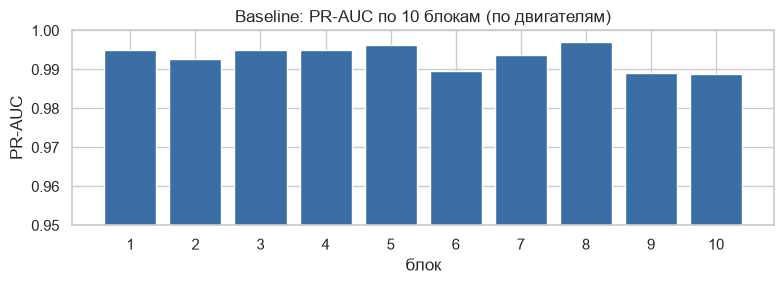

,fold,units,pr_auc,roc_auc
0,0,10,0.9950,0.9991
1,1,10,0.9926,0.9986
2,2,10,0.9950,0.9991
3,3,10,0.9949,0.9991
4,4,10,0.9963,0.9993
5,5,10,0.9895,0.9984
6,6,10,0.9938,0.9988
7,7,10,0.9971,0.9995
8,8,10,0.9890,0.9979
9,9,10,0.9890,0.9980


In [3]:
folds = res["_folds"]
print(f"PR-AUC по блокам: среднее {folds['pr_auc'].mean():.4f}, ст. отклонение {folds['pr_auc'].std():.4f}, "
      f"min {folds['pr_auc'].min():.4f}, max {folds['pr_auc'].max():.4f}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(folds["fold"] + 1, folds["pr_auc"], color="#3b6ea5")
ax.set(ylim=(0.95, 1.0), xlabel="блок", ylabel="PR-AUC", title="Baseline: PR-AUC по 10 блокам (по двигателям)")
ax.set_xticks(folds["fold"] + 1)
plt.tight_layout(); plt.show()
folds

## 3. Выбор порога

Как меняются Recall и FPR на предсказаниях кросс-валидации в зависимости от порога.

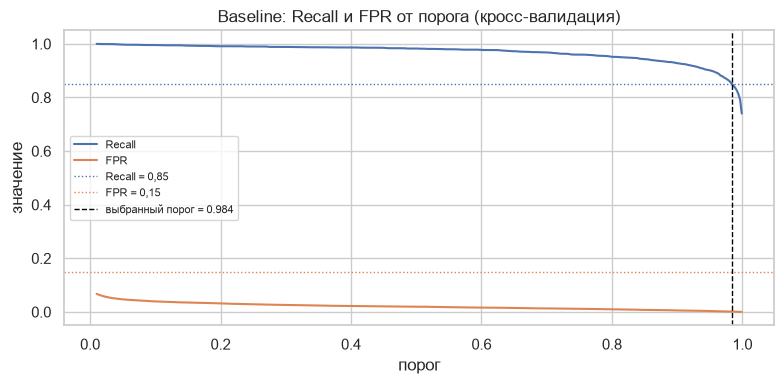

In [4]:
y = train["target"].to_numpy()
oof = res["_oof"]
grid = np.linspace(0.01, 0.999, 400)
rec = [((oof >= t) & (y == 1)).sum() / (y == 1).sum() for t in grid]
fpr = [((oof >= t) & (y == 0)).sum() / (y == 0).sum() for t in grid]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, rec, label="Recall")
ax.plot(grid, fpr, label="FPR")
ax.axhline(MIN_RECALL, color="C0", ls=":", lw=1, label="Recall = 0,85")
ax.axhline(MAX_FPR, color="C1", ls=":", lw=1, label="FPR = 0,15")
ax.axvline(thr, color="black", ls="--", lw=1, label=f"выбранный порог = {thr:.3f}")
ax.set(xlabel="порог", ylabel="значение", title="Baseline: Recall и FPR от порога (кросс-валидация)")
ax.legend(fontsize=8, loc="center left")
plt.tight_layout(); fig.savefig(FIG_DIR / "02_threshold.png", dpi=120); plt.show()

## 4. PR-кривые: кросс-валидация и test

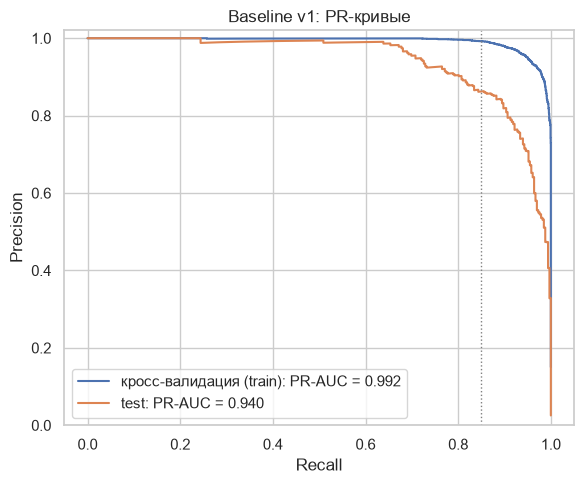

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, yt, p in [("кросс-валидация (train)", y, oof), ("test", test["target"], res["_test_proba"])]:
    pr, rc, _ = precision_recall_curve(yt, p)
    ax.plot(rc, pr, label=f"{name}: PR-AUC = {average_precision_score(yt, p):.3f}")
ax.axvline(MIN_RECALL, color="grey", ls=":", lw=1)
ax.set(xlabel="Recall", ylabel="Precision", title="Baseline v1: PR-кривые", ylim=(0, 1.02))
ax.legend(loc="lower left")
plt.tight_layout(); fig.savefig(FIG_DIR / "02_pr_curves.png", dpi=120); plt.show()

## 5. Почему Recall на test ниже

На test наблюдения двигателей обрываются до отказа, поэтому положительные примеры распределены по RUL иначе,
чем в train. Сравним Recall внутри одинаковых диапазонов RUL.

In [6]:
def recall_by_rul(df, proba):
    d = df.assign(pred=(proba >= thr).astype(int))
    d = d[d["target"] == 1]
    g = d.groupby(pd.cut(d["rul"], [-1, 10, 20, 30], labels=["0–10", "11–20", "21–30"]), observed=True)["pred"]
    return pd.DataFrame({"строк": g.size(), "доля строк": g.size() / len(d), "Recall": g.mean()})

by_rul = pd.concat({"кросс-валидация": recall_by_rul(train, oof), "test": recall_by_rul(test, res["_test_proba"])}, axis=1)
by_rul

кросс-валидация                    test                   
                строк доля строк Recall строк доля строк  Recall
rul                                                             
0–10             1100     0.3548  1.000    17     0.0512  1.0000
11–20            1000     0.3226  0.979   106     0.3193  0.9717
21–30            1000     0.3226  0.556   209     0.6295  0.5024

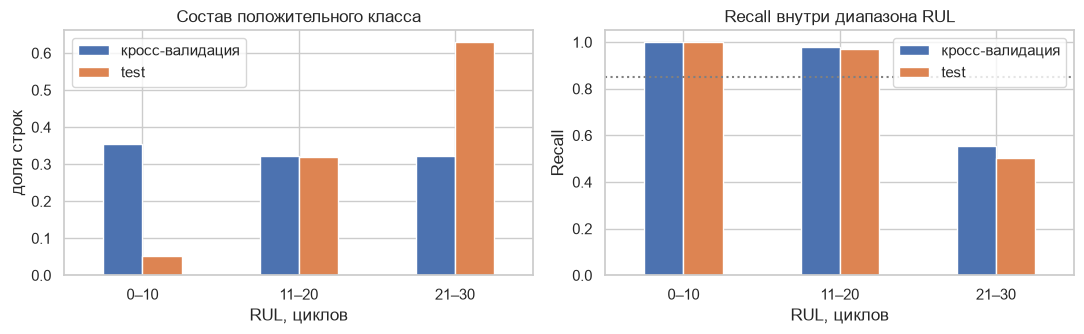

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
by_rul.xs("доля строк", axis=1, level=1).plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Состав положительного класса", xlabel="RUL, циклов", ylabel="доля строк")
by_rul.xs("Recall", axis=1, level=1).plot.bar(ax=ax[1], rot=0)
ax[1].axhline(MIN_RECALL, color="grey", ls=":")
ax[1].set(title="Recall внутри диапазона RUL", xlabel="RUL, циклов", ylabel="Recall")
plt.tight_layout(); fig.savefig(FIG_DIR / "02_recall_by_rul.png", dpi=120); plt.show()

## 6. Бизнес-метрики уровня двигателя

Доля двигателей, по которым была тревога в последние 30 циклов перед отказом, и запас времени от первой тревоги до отказа (цель из блока 1: медиана ≥ 15 циклов).

In [8]:
pd.DataFrame(res["engine_level"]).T

,engines,detected_share,median_lead,min_lead
cv_oof,100.0,1.00,26.0,10.0
test,25.0,0.76,27.0,20.0


## 7. Проверка на утечку данных

Если бы в признаках была «подсказка» о будущем, высокое качество получилось бы и без информативных признаков. Сравним ту же модель на разных наборах признаков (та же кросс-валидация).

In [9]:
rows = []
for name, cols in [("только номер цикла", ["cycle"]),
                   ("исходные датчики (14)", FEATURE_SENSORS),
                   ("все признаки (71)", FEATURE_COLS)]:
    X, yy, g = split_xy(train, cols)
    p, f = cross_validate_oof(make_baseline(), X, yy, g)
    rows.append({"набор признаков": name, "PR-AUC (OOF)": average_precision_score(yy, p),
                 "PR-AUC по блокам, среднее": f["pr_auc"].mean()})
leak = pd.DataFrame(rows).set_index("набор признаков")
leak

,PR-AUC (OOF),"PR-AUC по блокам, среднее"
набор признаков,,
только номер цикла,0.5087,0.5554
исходные датчики (14),0.9476,0.9502
все признаки (71),0.9918,0.9932


## 8. Какие признаки важны для модели

Коэффициенты логистической регрессии на стандартизированных признаках: знак — направление влияния на вероятность отказа, модуль — сила.

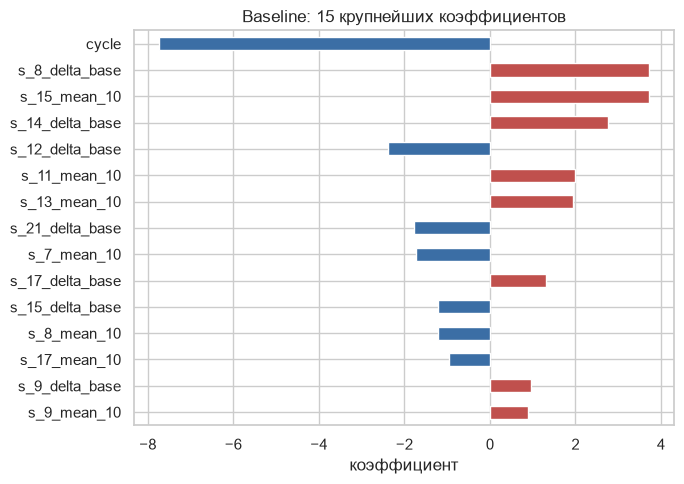

In [10]:
coef = pd.Series(res["_model"].named_steps["clf"].coef_[0], index=FEATURE_COLS)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
top[::-1].plot.barh(ax=ax, color=np.where(top[::-1] > 0, "#c0504d", "#3b6ea5"))
ax.set(title="Baseline: 15 крупнейших коэффициентов", xlabel="коэффициент")
plt.tight_layout(); fig.savefig(FIG_DIR / "02_coefficients.png", dpi=120); plt.show()

## 9. Время предсказания

In [11]:
res["latency_single_row"]

{'p50_ms': 1.4028499135747552, 'p95_ms': 1.8836399074643844, 'n': 500}

## 10. Выводы

- **Baseline v1 на кросс-валидации:** PR-AUC 0,992 (по блокам 0,993 ± 0,003), при пороге 0,984 — Recall 0,85,
  FPR 0,001, F2 0,875. Оба требования выполнены.
- **Утечки нет:** номер цикла сам по себе даёт PR-AUC 0,51, исходные датчики — 0,948, признаки по истории
  поднимают результат до 0,992. Это предварительно поддерживает гипотезу H1 (формальная проверка — в блоке 3.2).
- **На test требование по Recall не выполнено:** Recall 0,678 (нужно ≥ 0,85), FPR 0,0004 (требование выполнено),
  PR-AUC 0,940.
- **Причина — состав test, а не переобучение:** внутри одинаковых диапазонов RUL Recall на кросс-валидации и test
  почти одинаков (для RUL 21–30: 0,56 и 0,50). Но в test 63% положительных строк приходятся на трудный
  диапазон RUL 21–30 против 32% в train: наблюдения тестовых двигателей обрываются, не дойдя до отказа.
- **Порог выбран «впритык»:** правило «наибольший порог с Recall ≥ 0,85» минимизирует ложные тревоги, но
  оставляет Recall ровно на границе, а запас по FPR огромный (0,001 при допустимых 0,15). Небольшой сдвиг
  данных выводит Recall ниже требования. Правило выбора порога с запасом нужно определить **по train**
  (не подгоняя под test) — это задача блоков 3.2–3.3.
- **Бизнес-метрики:** на кросс-валидации тревога поднята для всех 100 двигателей, медианный запас — 26 циклов
  (цель ≥ 15). На test — для 19 из 25 двигателей, чьи наблюдения доходят до последних 30 циклов (76%).
- **Время предсказания** одной строки: p95 ≈ 2 мс (требование — 50 мс на весь запрос, проверяется в блоке 5).